In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

In [3]:
ufo = pd.read_csv("nuforc_reports.csv")

ufo.head()
ufo.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 88125 entries, 0 to 88124
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   summary         88095 non-null  object 
 1   city            87888 non-null  object 
 2   state           82890 non-null  object 
 3   date_time       86938 non-null  object 
 4   shape           85627 non-null  object 
 5   duration        84951 non-null  object 
 6   stats           88088 non-null  object 
 7   report_link     88125 non-null  object 
 8   text            88070 non-null  object 
 9   posted          86938 non-null  object 
 10  city_latitude   72013 non-null  float64
 11  city_longitude  72013 non-null  float64
dtypes: float64(2), object(10)
memory usage: 8.1+ MB


In [4]:
# Standardize column names
ufo.columns = [c.strip().lower().replace(" ", "_") for c in ufo.columns]
ufo.columns

Index(['summary', 'city', 'state', 'date_time', 'shape', 'duration', 'stats',
       'report_link', 'text', 'posted', 'city_latitude', 'city_longitude'],
      dtype='object')

In [8]:
ufo['date_time'] = pd.to_datetime(ufo['date_time'], errors='coerce')

ufo['year'] = ufo['date_time'].dt.year
ufo['month'] = ufo['date_time'].dt.month
ufo['day'] = ufo['date_time'].dt.day
ufo['hour'] = ufo['date_time'].dt.hour

In [9]:
def get_season(month):
    if month in [12, 1, 2]:
        return 'winter'
    elif month in [3, 4, 5]:
        return 'spring'
    elif month in [6, 7, 8]:
        return 'summer'
    else:
        return 'fall'

ufo['season'] = ufo['month'].apply(get_season)

In [10]:
ufo['state'] = ufo['state'].str.upper().str.strip()
ufo['city'] = ufo['city'].str.title().str.strip()

# Drop rows with missing state
ufo = ufo[~ufo['state'].isna()].copy()

In [11]:
ufo['shape'] = ufo['shape'].str.lower().str.strip()

common_shapes = ['light', 'circle', 'triangle', 'disk', 'sphere', 'fireball']
ufo['shape_clean'] = np.where(ufo['shape'].isin(common_shapes), ufo['shape'], 'unknown')

In [12]:
ufo['duration_sec'] = (
    ufo['duration']
    .str.extract(r'(\d+\.?\d*)', expand=False)
    .astype(float)
)

ufo['duration_log'] = np.log1p(ufo['duration_sec'])

In [13]:
cols_check = ['state', 'city', 'shape_clean', 'duration_sec', 'text']
missing_counts = ufo[cols_check].isna().sum()
missing_percent = missing_counts / len(ufo) * 100

print("Missing value counts:\n", missing_counts)
print("\nMissing value percentages:\n", missing_percent)

Missing value counts:
 state              0
city             122
shape_clean        0
duration_sec    8063
text              52
dtype: int64

Missing value percentages:
 state           0.000000
city            0.147183
shape_clean     0.000000
duration_sec    9.727349
text            0.062734
dtype: float64


In [14]:
ufo['is_night'] = ufo['hour'].apply(lambda h: 1 if (h >= 18 or h < 6) else 0)

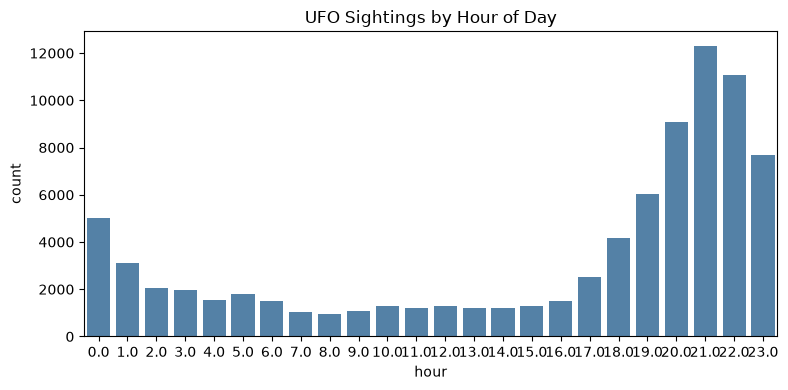

In [15]:
plt.figure(figsize=(8, 4))
sns.countplot(x='hour', data=ufo, color='steelblue')
plt.title('UFO Sightings by Hour of Day')
plt.tight_layout()
plt.show()

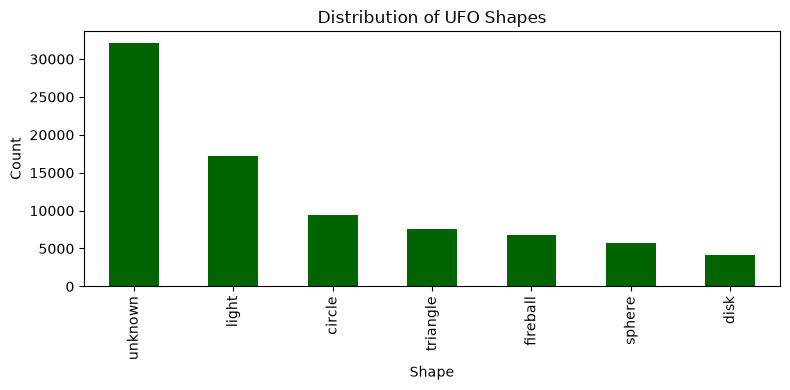

In [16]:
plt.figure(figsize=(8, 4))
ufo['shape_clean'].value_counts().plot(kind='bar', color='darkgreen')
plt.title('Distribution of UFO Shapes')
plt.xlabel('Shape')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

In [17]:
ufo['duration_bin'] = pd.cut(
    ufo['duration_sec'],
    bins=[0, 60, 300, np.inf],
    labels=['short', 'medium', 'long']
)

In [18]:
def time_bin(h):
    if h < 6:
        return 'early_morning'
    elif h < 12:
        return 'morning'
    elif h < 18:
        return 'afternoon'
    else:
        return 'evening'

ufo['time_bin'] = ufo['hour'].apply(time_bin)

In [19]:
categorical_cols = ['shape_clean', 'season', 'duration_bin', 'time_bin']
ufo_dummies = pd.get_dummies(ufo[categorical_cols], prefix=categorical_cols)

ufo_dummies['is_night'] = ufo['is_night']

ufo_dummies.head()

,shape_clean_circle,shape_clean_disk,shape_clean_fireball,shape_clean_light,shape_clean_sphere,shape_clean_triangle,shape_clean_unknown,season_fall,season_spring,season_summer,season_winter,duration_bin_short,duration_bin_medium,duration_bin_long,time_bin_afternoon,time_bin_early_morning,time_bin_evening,time_bin_morning,is_night
0,False,False,False,True,False,False,False,False,False,False,True,True,False,False,False,False,True,False,1
1,True,False,False,False,False,False,False,False,True,False,False,True,False,False,False,False,True,False,1
3,False,False,False,False,False,False,True,False,True,False,False,True,False,False,False,True,False,False,1
4,False,False,False,False,False,False,True,False,True,False,False,True,False,False,False,False,True,False,1
5,False,True,False,False,False,False,False,False,True,False,False,True,False,False,False,False,True,False,1


In [20]:
freq_items_apriori = apriori(
    ufo_dummies.astype(bool),
    min_support=0.05,
    use_colnames=True
)

freq_items_apriori.sort_values('support', ascending=False).head(20)

,support,itemsets
11,0.890867,(duration_bin_short)
16,0.793799,(is_night)
59,0.713753,"(duration_bin_short, is_night)"
14,0.619990,(time_bin_evening)
61,0.607214,"(is_night, time_bin_evening)"
57,0.563132,"(duration_bin_short, time_bin_evening)"
108,0.552636,"(duration_bin_short, is_night, time_bin_evening)"
6,0.386729,(shape_clean_unknown)
37,0.333285,"(duration_bin_short, shape_clean_unknown)"
9,0.319158,(season_summer)


In [21]:
freq_items_fpgrowth = fpgrowth(
    ufo_dummies.astype(bool),
    min_support=0.05,
    use_colnames=True
)

freq_items_fpgrowth.sort_values('support', ascending=False).head(20)

,support,itemsets
0,0.890867,(duration_bin_short)
1,0.793799,(is_night)
17,0.713753,"(duration_bin_short, is_night)"
2,0.619990,(time_bin_evening)
18,0.607214,"(is_night, time_bin_evening)"
19,0.563132,"(duration_bin_short, time_bin_evening)"
20,0.552636,"(duration_bin_short, is_night, time_bin_evening)"
7,0.386729,(shape_clean_unknown)
63,0.333285,"(duration_bin_short, shape_clean_unknown)"
12,0.319158,(season_summer)


In [22]:
rules = association_rules(freq_items_apriori, metric="lift", min_threshold=1.0)

rules_sorted = rules.sort_values('lift', ascending=False)
rules_sorted.head(20)

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
170,"(is_night, shape_clean_unknown)",(time_bin_early_morning),0.288069,0.186585,0.077742,0.269872,1.446378,1.0,0.023992,1.114072,0.433493,0.195866,0.102392,0.343264
175,(time_bin_early_morning),"(is_night, shape_clean_unknown)",0.186585,0.288069,0.077742,0.416656,1.446378,1.0,0.023992,1.220431,0.379410,0.195866,0.180618,0.343264
272,"(shape_clean_fireball, is_night)","(duration_bin_short, time_bin_evening)",0.072023,0.563132,0.056448,0.783752,1.391774,1.0,0.015890,2.020219,0.303340,0.097542,0.505004,0.441996
277,"(duration_bin_short, time_bin_evening)","(shape_clean_fireball, is_night)",0.563132,0.072023,0.056448,0.100240,1.391774,1.0,0.015890,1.031360,0.644342,0.097542,0.030407,0.441996
360,"(is_night, shape_clean_unknown)","(duration_bin_short, time_bin_early_morning)",0.288069,0.161117,0.064145,0.222674,1.382060,1.0,0.017732,1.079190,0.388299,0.166594,0.073379,0.310401
359,"(duration_bin_short, time_bin_early_morning)","(is_night, shape_clean_unknown)",0.161117,0.288069,0.064145,0.398128,1.382060,1.0,0.017732,1.182862,0.329536,0.166594,0.154593,0.310401
354,"(duration_bin_short, is_night, shape_clean_unk...",(time_bin_early_morning),0.251538,0.186585,0.064145,0.255012,1.366736,1.0,0.017212,1.091850,0.358509,0.171522,0.084124,0.299399
365,(time_bin_early_morning),"(duration_bin_short, is_night, shape_clean_unk...",0.186585,0.251538,0.064145,0.343786,1.366736,1.0,0.017212,1.140576,0.329881,0.171522,0.123250,0.299399
280,(time_bin_evening),"(shape_clean_fireball, is_night, duration_bin_...",0.619990,0.066824,0.056448,0.091047,1.362501,1.0,0.015018,1.026650,0.700128,0.089549,0.025958,0.467892
269,"(shape_clean_fireball, is_night, duration_bin_...",(time_bin_evening),0.066824,0.619990,0.056448,0.844737,1.362501,1.0,0.015018,2.447527,0.285107,0.089549,0.591424,0.467892
